# 01 · Dados: 197 mil entregas do DoorDash

Dataset publicado pelo DoorDash como teste técnico pra candidatos (*DoorDash ETA Prediction*): entregas de comida entre 21/01 e 18/02/2015, em 6 mercados (cidades) dos EUA. A empresa adicionou ruído pra esconder detalhes do negócio.

O que tem em cada pedido:
- **pedido:** itens, valor, preço do item mais barato e do mais caro
- **loja:** id, categoria (pizza, mexicana...) e como recebe o pedido (`order_protocol`)
- **oferta x demanda no momento do pedido:** entregadores online, entregadores ocupados, pedidos na fila
- **estimativas da própria plataforma:** tempo pra loja receber o pedido e tempo de deslocamento até o cliente
- **alvo:** tempo total do pedido até a entrega

Os horários estão em **UTC**. O dataset não informa o fuso de cada mercado.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# paleta categórica validada (daltonismo) + estilo discreto
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from eta import load

df = load(verbose=True)
df[["created_at", "actual_delivery_time", "minutos", "market_id", "store_primary_category",
    "total_items", "subtotal", "total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders"]].head()

197428 linhas -> 197280 entregas válidas (148 removidas: sem horário de entrega, fora do período ou fora de 5–180 min)


,created_at,actual_delivery_time,minutos,market_id,store_primary_category,total_items,subtotal,total_onshift_dashers,total_busy_dashers,total_outstanding_orders
0,2015-01-21 15:22:03,2015-01-21 16:17:43,55.666667,1.0,dessert,2,1058,2.0,1.0,1.0
1,2015-01-21 15:31:51,2015-01-21 16:16:34,44.716667,3.0,cafe,2,690,2.0,0.0,1.0
2,2015-01-21 15:39:16,2015-01-21 15:58:11,18.916667,1.0,NaN,3,1867,4.0,1.0,1.0
3,2015-01-21 15:40:42,2015-01-21 16:22:37,41.916667,1.0,cafe,3,955,3.0,2.0,2.0
4,2015-01-21 15:41:33,2015-01-21 16:35:14,53.683333,1.0,chinese,3,825,0.0,0.0,0.0


## Divisão temporal

Os dados são divididos **por data**, nunca aleatoriamente: o modelo sempre é avaliado em dias que ele não viu, como seria em produção.

In [3]:
resumo = df.groupby("periodo", sort=False).agg(
    inicio=("created_at", "min"), fim=("created_at", "max"), entregas=("id", "size"),
    mediana_min=("minutos", "median"), p90_min=("minutos", lambda s: s.quantile(0.9)))
resumo["inicio"] = resumo["inicio"].dt.strftime("%d/%m"); resumo["fim"] = resumo["fim"].dt.strftime("%d/%m")
resumo.round(1)

,inicio,fim,entregas,mediana_min,p90_min
periodo,,,,,
treino,21/01,03/02,89219,44.4,71.3
validacao,04/02,08/02,38085,43.2,69.1
calibracao,09/02,11/02,19766,43.1,65.5
teste,12/02,18/02,50210,45.6,71.8


## Quanto tempo leva uma entrega?

10% chegam em até 28.3 min | mediana 44.3 min | 90% chegam em até 70.5 min


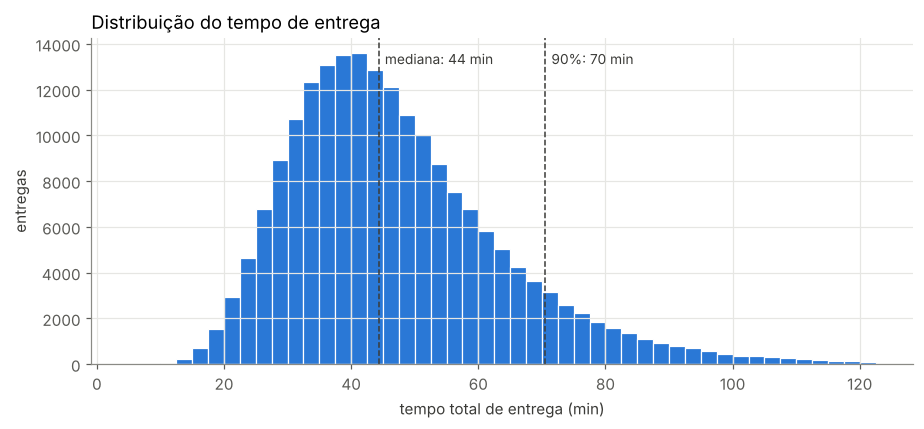

In [4]:
q = df["minutos"].quantile([0.1, 0.5, 0.9]).round(1)
print(f"10% chegam em até {q[0.1]} min | mediana {q[0.5]} min | 90% chegam em até {q[0.9]} min")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(df["minutos"], bins=np.arange(5, 125, 2.5), color=CORES[0], edgecolor="white", linewidth=0.8)
for v, rot in [(q[0.5], "mediana"), (q[0.9], "90%")]:
    ax.axvline(v, color="#3b3b38", lw=1, ls="--")
    ax.text(v + 1, ax.get_ylim()[1] * 0.92, f"{rot}: {v:.0f} min", fontsize=9, color="#3b3b38")
ax.set_xlabel("tempo total de entrega (min)"); ax.set_ylabel("entregas")
ax.set_title("Distribuição do tempo de entrega", loc="left")
plt.tight_layout(); plt.savefig("../results/distribuicao_tempo.png", dpi=150); plt.show()

A distribuição tem cauda longa à direita: a maioria das entregas leva de 30 a 60 minutos, mas algumas passam de 90. É por isso que um prazo de "mediana + margem fixa" funciona mal: a incerteza não é igual pra todo pedido.

## Dia a dia: a semana de teste é diferente

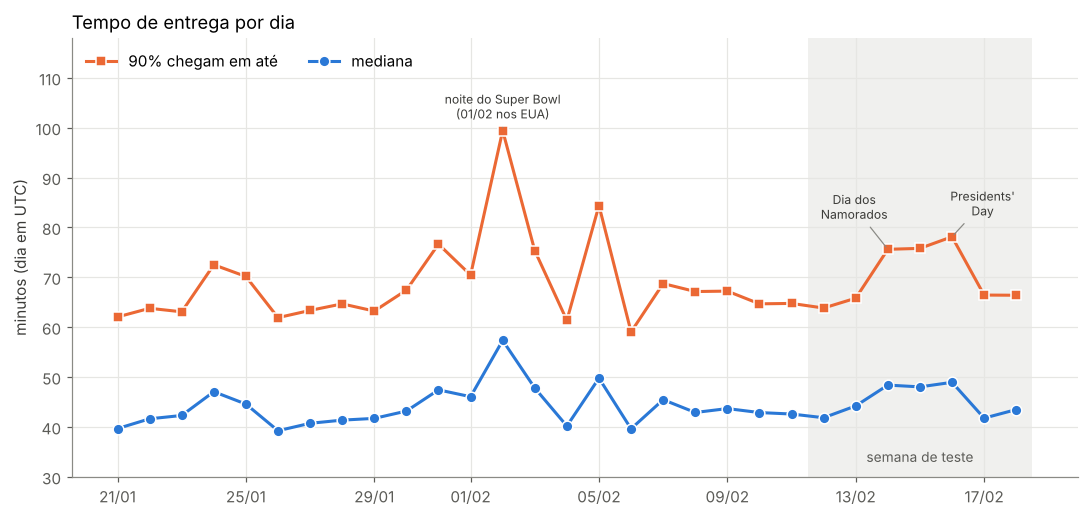

In [5]:
dia = df.groupby(df["created_at"].dt.floor("D"))["minutos"].agg(mediana="median", p90=lambda s: s.quantile(0.9), n="size")
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(pd.Timestamp("2015-02-11 12:00"), pd.Timestamp("2015-02-18 12:00"), color="#e6e6e3", alpha=0.6, lw=0)
ax.text(pd.Timestamp("2015-02-15"), 33, "semana de teste", ha="center", fontsize=9, color="#5c5c58")
ax.plot(dia.index, dia["p90"], color=CORES[1], marker="s", markeredgecolor="white", label="90% chegam em até")
ax.plot(dia.index, dia["mediana"], color=CORES[0], marker="o", markeredgecolor="white", label="mediana")
for d, rot, dx, dy in [("2015-02-02", "noite do Super Bowl\n(01/02 nos EUA)", 0, 8), ("2015-02-14", "Dia dos\nNamorados", -22, 20), ("2015-02-16", "Presidents'\nDay", 20, 14)]:
    v = dia.loc[pd.Timestamp(d), "p90"]
    ax.annotate(rot, (pd.Timestamp(d), v), xytext=(dx, dy), textcoords="offset points", ha="center", fontsize=8, color="#3b3b38",
                arrowprops=dict(arrowstyle="-", color="#8a8a85", lw=0.8))
ax.set_ylabel("minutos (dia em UTC)"); ax.set_ylim(30, 118)
ax.set_title("Tempo de entrega por dia", loc="left")
ax.legend(frameon=False, loc="upper left", ncol=2)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
plt.tight_layout(); plt.savefig("../results/tempo_por_dia.png", dpi=150); plt.show()

In [6]:
hora = df[(df["created_at"] >= "2015-02-01 20:00") & (df["created_at"] < "2015-02-02 06:00")]
hora.groupby(hora["created_at"].dt.floor("h")).agg(
    pedidos=("minutos", "size"), mediana_min=("minutos", "median"),
    fila=("total_outstanding_orders", "median"), entregadores=("total_onshift_dashers", "median")).round(1)

,pedidos,mediana_min,fila,entregadores
created_at,,,,
2015-02-01 20:00:00,518,42.3,36.0,33.0
2015-02-01 21:00:00,488,43.8,36.5,28.0
2015-02-01 22:00:00,399,42.6,26.5,23.0
2015-02-01 23:00:00,396,42.3,25.0,21.0
2015-02-02 00:00:00,622,44.2,35.0,28.0
2015-02-02 01:00:00,1177,60.0,66.0,45.0
2015-02-02 02:00:00,1291,81.6,94.0,48.0
2015-02-02 03:00:00,509,85.8,71.0,36.0
2015-02-02 04:00:00,362,54.1,55.0,40.0


Entre 01h e 03h UTC de 02/02 (noite de domingo, 01/02, nos EUA), a mediana chega a **82–86 minutos**, com ~94 pedidos na fila pra ~48 entregadores. O horário coincide com a noite do **Super Bowl** de 2015. É o mesmo tipo de pico em evento esportivo que plataformas como o iFood precisam antecipar.

In [7]:
print(dia.loc["2015-02-12":, ["mediana", "p90", "n"]].round(1).assign(dia=lambda d: d.index.strftime("%d/%m (%a)")).set_index("dia"))

             mediana   p90     n
dia                             
12/02 (Thu)     41.8  63.8  6763
13/02 (Fri)     44.2  65.8  7379
14/02 (Sat)     48.4  75.6  9010
15/02 (Sun)     48.0  75.8  9079
16/02 (Mon)     49.0  78.1  7927
17/02 (Tue)     41.8  66.4  6073
18/02 (Wed)     43.5  66.4  3979


A semana de teste também tem dias atípicos: **14/02** (Dia dos Namorados nos EUA, sábado) e **16/02** (Presidents' Day, feriado). Nesses dias, as entregas ficam mais lentas e o volume sobe. Isso torna o teste mais difícil e mais realista: em produção, o modelo também vai encontrar dias que não se parecem com o treino.

## Oferta x demanda: o que mais pesa

In [8]:
fila = df["total_outstanding_orders"] / df["total_onshift_dashers"].where(df["total_onshift_dashers"] > 0)
faixas = pd.cut(fila, [0, 0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 100], labels=["<0,5", "0,5–0,8", "0,8–1", "1–1,2", "1,2–1,5", "1,5–2", ">2"])
t = df.groupby(faixas, observed=True)["minutos"].agg(mediana="median", p90=lambda s: s.quantile(0.9), entregas="size")
t.round(1)

,mediana,p90,entregas
"<0,5",36.8,57.7,6522
"0,5–0,8",37.1,57.2,20286
"0,8–1",39.3,60.7,29913
"1–1,2",41.6,62.7,31502
"1,2–1,5",45.9,68.8,48367
"1,5–2",54.0,80.7,35360
>2,66.4,102.3,4726


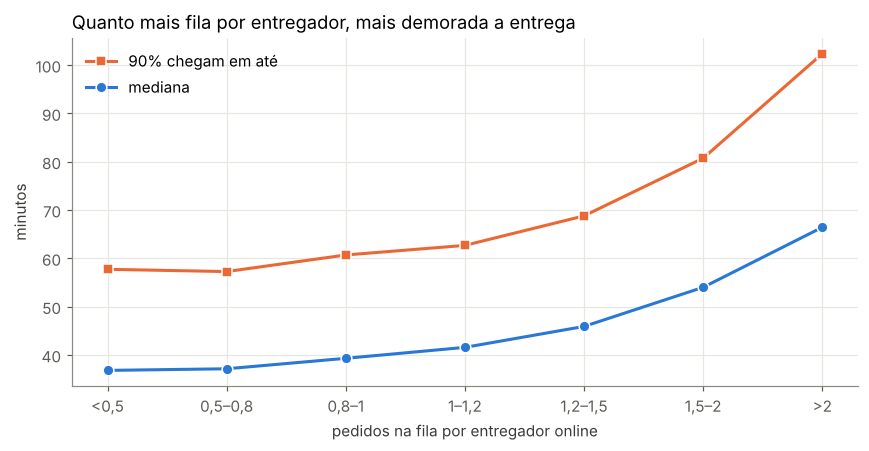

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(t))
ax.plot(x, t["p90"], color=CORES[1], marker="s", markeredgecolor="white", label="90% chegam em até")
ax.plot(x, t["mediana"], color=CORES[0], marker="o", markeredgecolor="white", label="mediana")
ax.set_xticks(x, t.index)
ax.set_xlabel("pedidos na fila por entregador online"); ax.set_ylabel("minutos")
ax.set_title("Quanto mais fila por entregador, mais demorada a entrega", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("../results/fila_por_entregador.png", dpi=150); plt.show()

Com menos de 0,5 pedido na fila por entregador, a mediana fica em ~37 minutos. Com mais de 2, ela vai a ~66 minutos, e os 10% mais lentos passam de 100 minutos. Essa variável de equilíbrio entre oferta e demanda vai ser a mais importante do modelo (notebook 02).